# Non-deep LDA: high-dimensional $\mu$ dynamics comparison

This notebook compares three dynamics for a $d$-dimensional two-class Gaussian LDA model with class means constrained to $\pm\mu$ and covariance $I_d$:

1. finite-sample gradient ascent,
2. population-level gradient ascent,
3. population-level gradient flow.

The model is
$$
x = y\mu^\star + \epsilon, \qquad y\in\{-1,1\}, \qquad \epsilon\sim N(0,I_d),
$$
so the population target is $\mathbb{E}[yx]=\mu^\star$. The dynamics are vector-valued:
$$
\mu_{k+1}=\mu_k+\alpha(\widehat m-\mu_k), \qquad \dot\mu(t)=\mu^\star-\mu(t).
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4.8)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 15
plt.rcParams["axes.titlesize"] = 17
plt.rcParams["axes.labelsize"] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
plt.rcParams["legend.fontsize"] = 12


In [2]:
# Experiment setup
rng = np.random.default_rng(7)

d = 10                    # ambient dimension
N = 400                   # finite sample size per run
n_runs = 200              # number of finite-sample runs
alpha = 0.1               # gradient ascent step size
steps = 80                # number of discrete updates
ci_z = 1.96               # 95% normal-approx confidence multiplier

# A nontrivial direction with unit norm, then scaled by signal_strength.
signal_strength = 2.0
direction = rng.normal(size=d)
direction = direction / np.linalg.norm(direction)
mu_true = signal_strength * direction
mu0 = np.zeros(d)

print(f"dimension d = {d}")
print(f"||mu_true|| = {np.linalg.norm(mu_true):.4f}")
print(f"finite-sample runs = {n_runs}, sample size per run = {N}")


dimension d = 10
||mu_true|| = 2.0000
finite-sample runs = 200, sample size per run = 400


In [3]:
def run_gradient_ascent(mu_init: np.ndarray, target: np.ndarray, lr: float, num_steps: int) -> np.ndarray:
    """Discrete gradient ascent for dmu = target - mu."""
    mu_hist = np.empty((num_steps + 1, mu_init.size))
    mu_hist[0] = mu_init
    mu = mu_init.copy()
    for k in range(num_steps):
        grad = target - mu
        mu = mu + lr * grad
        mu_hist[k + 1] = mu
    return mu_hist


def alignment_fraction(mu_hist: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Projection onto mu_true, normalized so the optimum has value 1."""
    return mu_hist @ target / np.dot(target, target)


def error_norm(mu_hist: np.ndarray, target: np.ndarray) -> np.ndarray:
    return np.linalg.norm(mu_hist - target, axis=-1)


# (a) finite-sample gradient ascent over many independent datasets
m_hats = np.empty((n_runs, d))
mu_finite_ga_runs = np.empty((n_runs, steps + 1, d))

for r in range(n_runs):
    y = rng.choice(np.array([-1.0, 1.0]), size=N)
    eps = rng.standard_normal(size=(N, d))
    x = y[:, None] * mu_true[None, :] + eps
    m_hat_r = np.mean(y[:, None] * x, axis=0)

    m_hats[r] = m_hat_r
    mu_finite_ga_runs[r] = run_gradient_ascent(mu0, m_hat_r, alpha, steps)

# (b) population gradient ascent: target = mu_true
mu_population_ga = run_gradient_ascent(mu0, mu_true, alpha, steps)

# (c) population gradient flow: dmu/dt = mu_true - mu
t_grid = np.linspace(0.0, alpha * steps, steps + 1)
mu_population_gf = mu_true[None, :] + (mu0 - mu_true)[None, :] * np.exp(-t_grid[:, None])

finite_align_runs = alignment_fraction(mu_finite_ga_runs, mu_true)
finite_error_runs = error_norm(mu_finite_ga_runs, mu_true)

finite_align_mean = finite_align_runs.mean(axis=0)
finite_align_se = finite_align_runs.std(axis=0, ddof=1) / np.sqrt(n_runs)
finite_align_ci_lo = finite_align_mean - ci_z * finite_align_se
finite_align_ci_hi = finite_align_mean + ci_z * finite_align_se

finite_error_mean = finite_error_runs.mean(axis=0)
finite_error_se = finite_error_runs.std(axis=0, ddof=1) / np.sqrt(n_runs)
finite_error_ci_lo = finite_error_mean - ci_z * finite_error_se
finite_error_ci_hi = finite_error_mean + ci_z * finite_error_se

population_ga_align = alignment_fraction(mu_population_ga, mu_true)
population_gf_align = alignment_fraction(mu_population_gf, mu_true)
population_ga_error = error_norm(mu_population_ga, mu_true)
population_gf_error = error_norm(mu_population_gf, mu_true)

print(f"mean ||m_hat - mu_true|| = {np.linalg.norm(m_hats - mu_true, axis=1).mean():.4f}")
print(f"std  ||m_hat - mu_true|| = {np.linalg.norm(m_hats - mu_true, axis=1).std(ddof=1):.4f}")


mean ||m_hat - mu_true|| = 0.1538
std  ||m_hat - mu_true|| = 0.0333


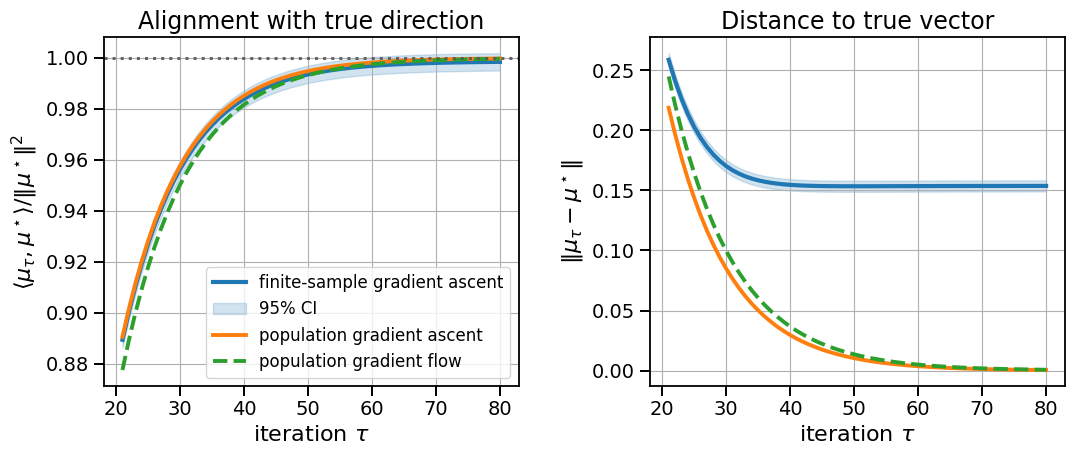

In [4]:
k_grid = np.arange(steps + 1)
last_k = 60
idx = slice(-last_k, None)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

# Alignment with the true direction
ax = axes[0]
ax.plot(k_grid[idx], finite_align_mean[idx], lw=3.0, color="C0", label="finite-sample gradient ascent")
ax.fill_between(k_grid[idx], finite_align_ci_lo[idx], finite_align_ci_hi[idx], color="C0", alpha=0.20, label="95% CI")
ax.plot(k_grid[idx], population_ga_align[idx], lw=2.8, color="C1", label="population gradient ascent")
ax.plot(k_grid[idx], population_gf_align[idx], "--", lw=2.8, color="C2", label="population gradient flow")
ax.axhline(1.0, color="0.35", ls=":", lw=2.2, alpha=0.9)
ax.set_title("Alignment with true direction")
ax.set_xlabel(r"iteration $\tau$")
ax.set_ylabel(r"$\langle\mu_\tau,\mu^\star\rangle/\|\mu^\star\|^2$")
ax.legend(loc="best", frameon=True)

# Distance to the true vector
ax = axes[1]
ax.plot(k_grid[idx], finite_error_mean[idx], lw=3.0, color="C0", label="finite-sample gradient ascent")
ax.fill_between(k_grid[idx], finite_error_ci_lo[idx], finite_error_ci_hi[idx], color="C0", alpha=0.20, label="95% CI")
ax.plot(k_grid[idx], population_ga_error[idx], lw=2.8, color="C1", label="population gradient ascent")
ax.plot(k_grid[idx], population_gf_error[idx], "--", lw=2.8, color="C2", label="population gradient flow")
ax.set_title("Distance to true vector")
ax.set_xlabel(r"iteration $\tau$")
ax.set_ylabel(r"$\|\mu_\tau-\mu^\star\|$")

for ax in axes:
    ax.tick_params(axis="both", which="major", direction="out", length=7, width=1.4)
    ax.tick_params(axis="both", which="minor", direction="out", length=4, width=1.1)
    for spine in ax.spines.values():
        spine.set_linewidth(1.3)

fig.tight_layout(w_pad=2.0)
plt.savefig("mu_dynamics_high_dim.png", dpi=600, bbox_inches="tight")
plt.show()
